# Logistic Regression — Sarcasm Detection

This notebook trains and evaluates a Logistic Regression model on the SARC dataset.
You need to run the projectText.ipynb first

**Pipeline:**
1. Load preprocessed data
2. Train/val/test split (90/10, seed = 42)
3. TF-IDF feature extraction
4. Train Logistic Regression with hyperparameter tuning (regularisation strength)
5. Evaluate on validation and test sets
6. Analysis: feature importance, error analysis, regularisation sensitivity

Also, while we used BERT tokenization in the preprocessing stage, it would not make sense to use the BERT token IDs as features, since the integer values are just arbitrary dictionary lookups (e.g. if token 2307 means 'great' and 2308 means 'green', logistic regression would interpret 2308 as being greater than 2307 which obviously doesnt make any sense here). BERT tokenization is more suited to deep neural networks where the tokenIds can be sent into embedding layers to learn meaning

However, for a simple logistic regression that we use as our baseline due to its simplicity, we do. not have the embedding layers to understand the tokenIds. Hence, we instead use TF-IDF as features

In detail, each dimension is a specific word (e.g. dim 0 is always the word "the", dimension 1 is always the word "oh"). So, for every comment, it can be summarized into a vector, where x_i = 0 if the word corresponding to the i-th dimension is not present. If the word is present, we instead give it the TF-IDF value (TF-IDF value = TF (term frequency; how often the word appears in the comment) x IDF (how rare this word is across all comments))

Note: while we can use 1/0 for present/absent, TF-IDF helps to downweight common words and upweight distinctive words, so the model can focus on words that are actually informative.

So, now logistic regression can learn one weight per word. For impactful words that determine whether the comment is sarcastic, the weight will be high and vice versa

The prediction for a new commenet is thus the summation of weight_of_word x tfidf_of_word for every word present -> apply sigmoid for prob

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

SEED = 42
np.random.seed(SEED)
print('Imports OK')

Imports OK


In [4]:
# load cleaned CSVs
train_df = pd.read_csv('../data/train_cleaned.csv')
test_df  = pd.read_csv('../data/test_cleaned.csv')

print(f'Train: {train_df.shape}, Test: {test_df.shape}')

Train: (1125667, 11), Test: (283332, 9)


In [5]:
# Split training dataset 
VAL_RATIO = 0.10

train_idx, val_idx = train_test_split(
    np.arange(len(train_df)),
    test_size=VAL_RATIO,
    stratify=train_df['label'],
    random_state=SEED,
)

train_subset = train_df.iloc[train_idx].reset_index(drop=True)
val_subset   = train_df.iloc[val_idx].reset_index(drop=True)

print(f'Train: {len(train_subset):,}  |  Val: {len(val_subset):,}  |  Test: {len(test_df):,}')
print(f'Train label dist: {train_subset["label"].value_counts().to_dict()}')
print(f'Val   label dist: {val_subset["label"].value_counts().to_dict()}')

Train: 1,013,100  |  Val: 112,567  |  Test: 283,332
Train label dist: {1: 506552, 0: 506548}
Val   label dist: {1: 56284, 0: 56283}


In [6]:
# Feature extraction -> we use TF-IDF to convert text into numerical features for logistic regression

TEXT_COL = 'text_normalized'


train_texts = train_subset[TEXT_COL].fillna('').astype(str)
val_texts   = val_subset[TEXT_COL].fillna('').astype(str)
test_texts  = test_df[TEXT_COL].fillna('').astype(str)

y_train = train_subset['label'].values
y_val   = val_subset['label'].values
y_test  = test_df['label'].values


tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    min_df=5,
    sublinear_tf=True,
    dtype=np.float32,     
)

X_train = tfidf.fit_transform(train_texts)
X_val   = tfidf.transform(val_texts)
X_test  = tfidf.transform(test_texts)

print(f'X_train: {X_train.shape} (sparse, {X_train.nnz:,} nonzeros)')
print(f'X_val:   {X_val.shape}')
print(f'X_test:  {X_test.shape}')
print(f'Vocabulary size: {len(tfidf.vocabulary_):,}')

X_train: (1013100, 50000) (sparse, 13,931,322 nonzeros)
X_val:   (112567, 50000)
X_test:  (283332, 50000)
Vocabulary size: 50,000


In [7]:
# For Logistic regression, we can choose to use L1 or L2 regularization, as well as the value of lambda (regression penalty)
# Hence, we sweep over different combinations of penalty type and regression penalty value

# Small C → strong regularisation → simpler model, may underfit
# Large C → weak regularisation → more complex model, may overfit
C_values = [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
penalties = ['l2', 'l1']
results = []

for penalty in penalties:
    for C in C_values:
        print(f'Training {penalty} C={C}...', end=' ')
        t0 = time.time()
        
        if penalty == 'l1':
            model = LogisticRegression(
                C=C, penalty='l1', solver='liblinear',
                max_iter=1000, random_state=SEED,
            )
        else:
            model = LogisticRegression(
                C=C, l1_ratio=0.0, solver='saga',
                max_iter=1000, random_state=SEED,
            )
        model.fit(X_train, y_train)
        
        train_acc = accuracy_score(y_train, model.predict(X_train))
        val_acc   = accuracy_score(y_val, model.predict(X_val))
        val_f1    = f1_score(y_val, model.predict(X_val))
        val_auc   = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
        
        n_nonzero = np.sum(model.coef_[0] != 0)
        elapsed = time.time() - t0
        
        results.append({
            'penalty': penalty, 'C': C,
            'train_acc': train_acc, 'val_acc': val_acc,
            'val_f1': val_f1, 'val_auc': val_auc,
            'n_nonzero': n_nonzero, 'time_s': elapsed,
            'n_iter': model.n_iter_[0]
        })
        print(f'val_acc={val_acc:.4f}, val_f1={val_f1:.4f}, '
              f'nonzero={n_nonzero:,}/{X_train.shape[1]:,} ({elapsed:.1f}s)')

results_df = pd.DataFrame(results)
print('\n')
print(results_df.to_string(index=False))

Training l2 C=0.001... val_acc=0.6557, val_f1=0.6239, nonzero=50,000/50,000 (8.2s)
Training l2 C=0.01... val_acc=0.6818, val_f1=0.6582, nonzero=50,000/50,000 (8.7s)
Training l2 C=0.1... val_acc=0.7129, val_f1=0.6976, nonzero=50,000/50,000 (9.2s)
Training l2 C=0.5... val_acc=0.7197, val_f1=0.7081, nonzero=50,000/50,000 (9.7s)
Training l2 C=1.0... 

/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


val_acc=0.7195, val_f1=0.7089, nonzero=50,000/50,000 (374.8s)
Training l2 C=5.0... 

/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


val_acc=0.7158, val_f1=0.7066, nonzero=50,000/50,000 (414.6s)
Training l2 C=10.0... val_acc=0.7144, val_f1=0.7053, nonzero=50,000/50,000 (22.4s)
Training l1 C=0.001... 

...

val_acc=0.7194, val_f1=0.7071, nonzero=28,467/50,000 (4.8s)
Training l1 C=5.0... 

/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


val_acc=0.7156, val_f1=0.7059, nonzero=44,957/50,000 (6.5s)
Training l1 C=10.0... 

/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


val_acc=0.7143, val_f1=0.7049, nonzero=47,401/50,000 (6.7s)


penalty      C  train_acc  val_acc   val_f1  val_auc  n_nonzero     time_s  n_iter
     l2  0.001   0.656020 0.655672 0.623865 0.710496      50000   8.242624      21
     l2  0.010   0.683679 0.681790 0.658167 0.745156      50000   8.672562      23
     l2  0.100   0.720451 0.712944 0.697594 0.781274      50000   9.164100      24
     l2  0.500   0.738629 0.719722 0.708097 0.791529      50000   9.682850      25
     l2  1.000   0.743076 0.719465 0.708920 0.791955      50000 374.844585    1000
     l2  5.000   0.747036 0.715840 0.706592 0.788360      50000 414.581210    1000
     l2 10.000   0.747323 0.714392 0.705278 0.786534      50000  22.422821      64
     l1  0.001   0.551162 0.551405 0.302537 0.551232          3   1.073572       6
     l1  0.010   0.639328 0.639637 0.586733 0.688188        202   1.652454      12
     l1  0.100   0.697748 0.696163 0.673533 0.761970       3025   2.978062      14
     l1  0.500   0.730549

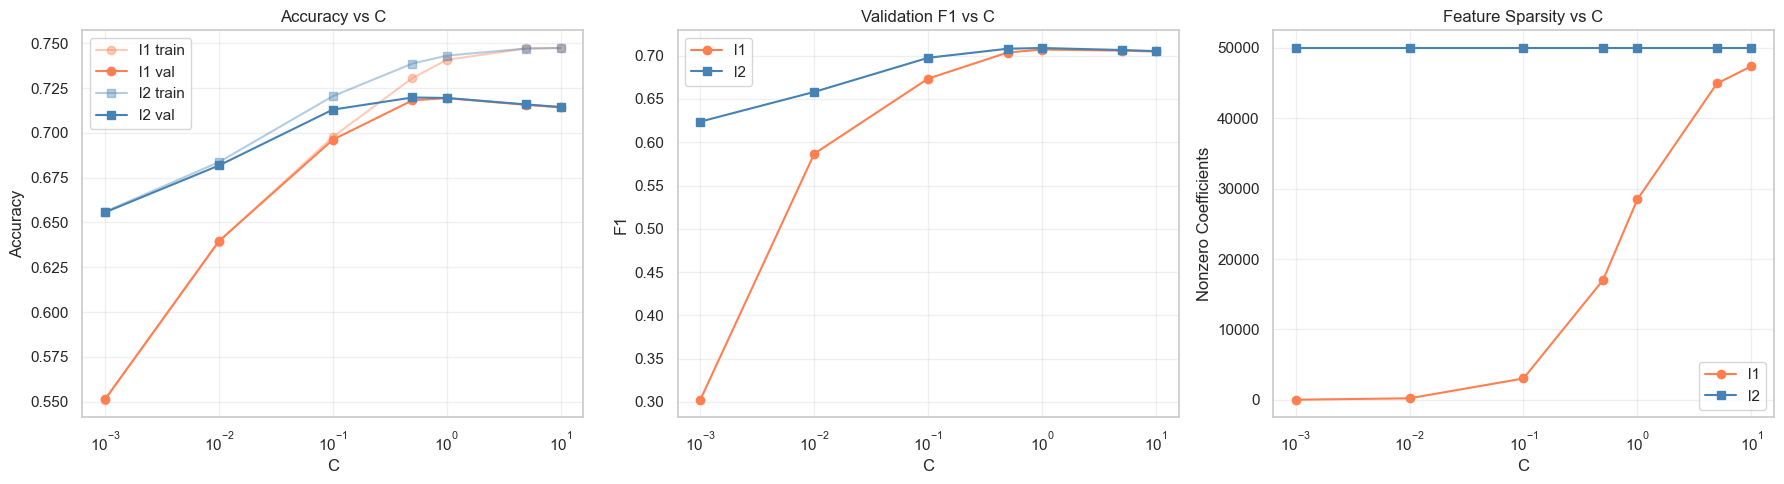


Best config: penalty=l2, C=1.0, val_f1=0.7089, val_acc=0.7195, nonzero=50,000


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for penalty, style, color in [('l1', 'o-', 'coral'), ('l2', 's-', 'steelblue')]:
    subset = results_df[results_df['penalty'] == penalty]
    
    axes[0].plot(subset['C'], subset['train_acc'], style, color=color, alpha=0.4, label=f'{penalty} train')
    axes[0].plot(subset['C'], subset['val_acc'], style, color=color, label=f'{penalty} val')
    axes[1].plot(subset['C'], subset['val_f1'], style, color=color, label=f'{penalty}')
    axes[2].plot(subset['C'], subset['n_nonzero'], style, color=color, label=f'{penalty}')

axes[0].set_xscale('log')
axes[0].set_xlabel('C')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs C')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log')
axes[1].set_xlabel('C')
axes[1].set_ylabel('F1')
axes[1].set_title('Validation F1 vs C')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].set_xscale('log')
axes[2].set_xlabel('C')
axes[2].set_ylabel('Nonzero Coefficients')
axes[2].set_title('Feature Sparsity vs C')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

best_row = results_df.loc[results_df['val_f1'].idxmax()]
print(f'\nBest config: penalty={best_row["penalty"]}, C={best_row["C"]}, '
      f'val_f1={best_row["val_f1"]:.4f}, val_acc={best_row["val_acc"]:.4f}, '
      f'nonzero={best_row["n_nonzero"]:,}')

In [9]:
# Now, after obtaining the best combination, we retrain the model using the best parameters, 
# and evaulate it on the held out test set

def evaluate(model, X, y_true, set_name='Test'):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auc  = roc_auc_score(y_true, y_prob)
    
    print(f'\n=== {set_name} Results ===')
    print(f'Accuracy:  {acc:.4f}')
    print(f'Precision: {prec:.4f}')
    print(f'Recall:    {rec:.4f}')
    print(f'F1 Score:  {f1:.4f}')
    print(f'ROC AUC:   {auc:.4f}')
    print(f'\nClassification Report:')
    print(classification_report(y_true, y_pred, target_names=['Not Sarcastic', 'Sarcastic']))
    
    return y_pred, y_prob

best_C = results_df.loc[results_df['val_f1'].idxmax(), 'C']
best_penalty = results_df.loc[results_df['val_f1'].idxmax(), 'penalty']
print(f'Retraining with best: penalty={best_penalty}, C={best_C}...')

if best_penalty == 'l1':
    best_model = LogisticRegression(
        C=best_C, penalty='l1', solver='liblinear',
        max_iter=1000, random_state=SEED,
    )
else:
    best_model = LogisticRegression(
        C=best_C, l1_ratio=0.0, solver='saga',
        max_iter=1000, random_state=SEED,
    )
best_model.fit(X_train, y_train)

test_pred, test_prob = evaluate(best_model, X_test, y_test, 'Test')

Retraining with best: penalty=l2, C=1.0...

=== Test Results ===
Accuracy:  0.7198
Precision: 0.7354
Recall:    0.6866
F1 Score:  0.7102
ROC AUC:   0.7911

Classification Report:
               precision    recall  f1-score   support

Not Sarcastic       0.71      0.75      0.73    141666
    Sarcastic       0.74      0.69      0.71    141666

     accuracy                           0.72    283332
    macro avg       0.72      0.72      0.72    283332
 weighted avg       0.72      0.72      0.72    283332



/path/to/Desktop/CS3244 Project/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


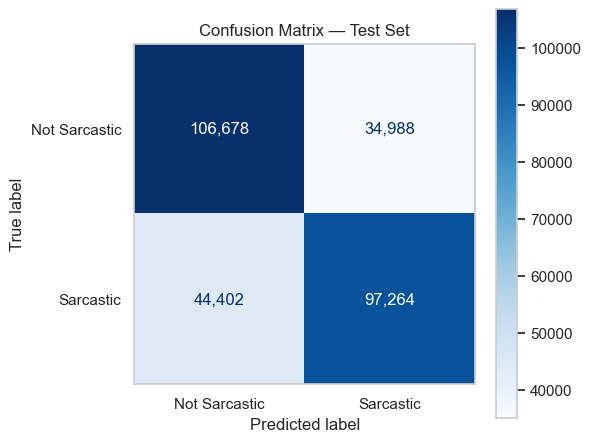

In [10]:
# Confusion matrix
fig, ax = plt.subplots(1, 1, figsize=(6, 5))
cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Sarcastic', 'Sarcastic']
)
disp.plot(cmap='Blues', ax=ax, values_format=',d')
ax.grid(False)
ax.set_title('Confusion Matrix — Test Set')
plt.tight_layout()
plt.show()

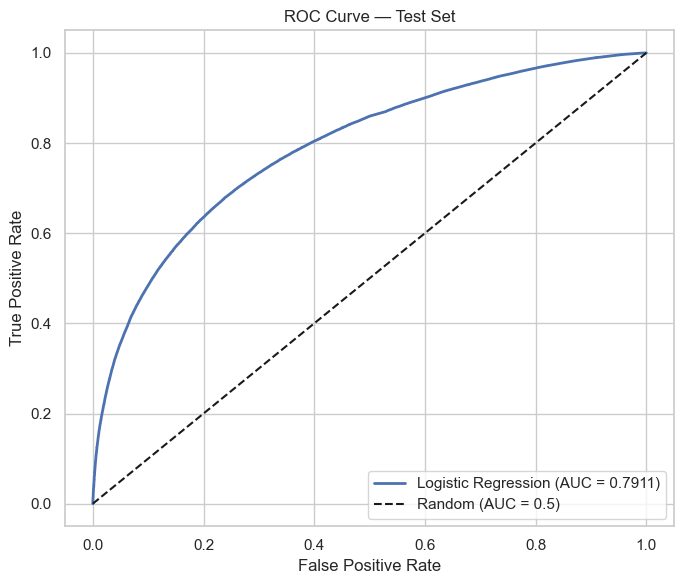

In [11]:
# ROC curve on test set
fpr, tpr, thresholds = roc_curve(y_test, test_prob)
auc_test = roc_auc_score(y_test, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_test:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Test Set')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Now, we dive deeper into the model -- ablation tests, exploring important coefficients

In [12]:
# Top features in the model
feature_names = tfidf.get_feature_names_out()
coefficients = best_model.coef_[0]

top_k = 30
top_sarcasm_idx = np.argsort(coefficients)[-top_k:][::-1]
top_nonsarc_idx = np.argsort(coefficients)[:top_k]

print(f'Top {top_k} features predicting SARCASM:')
for i in top_sarcasm_idx:
    print(f'  {feature_names[i]:30s}  coef={coefficients[i]:.4f}')

print(f'\nTop {top_k} features predicting NON-SARCASM:')
for i in top_nonsarc_idx:
    print(f'  {feature_names[i]:30s}  coef={coefficients[i]:.4f}')

Top 30 features predicting SARCASM:
  yes because                     coef=9.3340
  yeah because                    coef=7.5439
  clearly                         coef=7.4419
  obviously                       coef=7.3926
  totally                         coef=6.4237
  because                         coef=6.1242
  dropped this                    coef=6.0869
  how dare                        coef=5.8087
  good thing                      coef=5.5362
  right because                   coef=5.2552
  duh                             coef=5.2484
  imagine why                     coef=5.2432
  therefore                       coef=4.8504
  forgot this                     coef=4.8195
  not like                        coef=4.7863
  gee                             coef=4.7422
  shitlord                        coef=4.5397
  yeah fuck                       coef=4.4518
  psh                             coef=4.3746
  scrub                           coef=4.3640
  yes sure                        coef=4.350

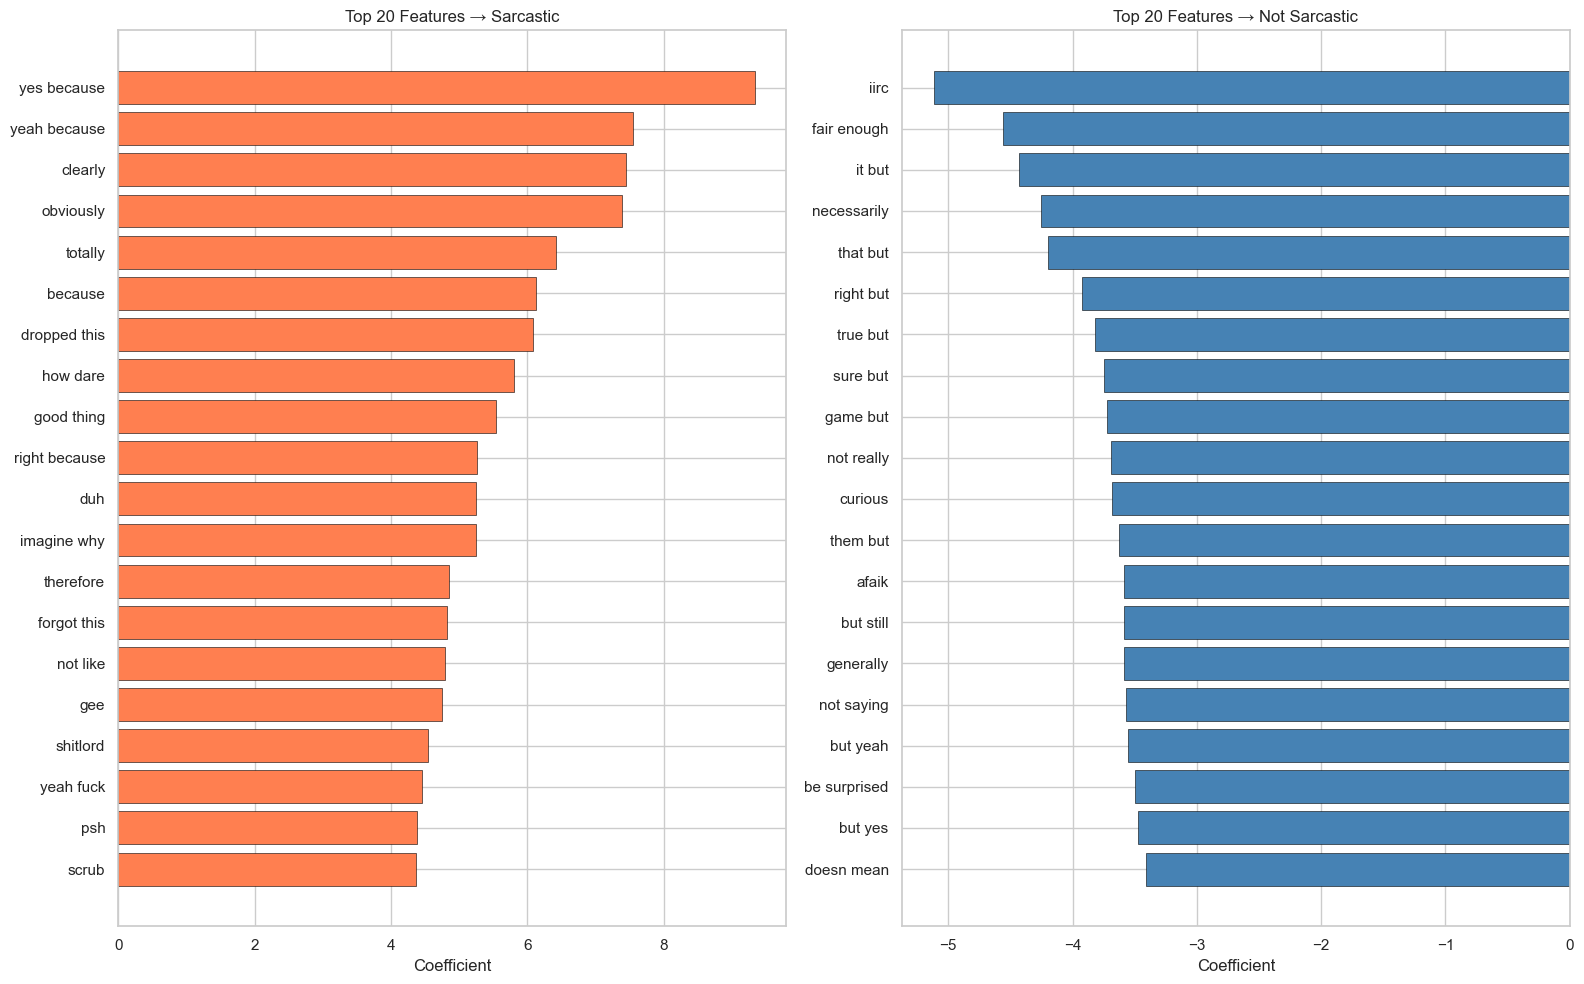

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

top_sarc_names = feature_names[top_sarcasm_idx[:20]]
top_sarc_coefs = coefficients[top_sarcasm_idx[:20]]
axes[0].barh(range(len(top_sarc_names)), top_sarc_coefs[::-1], color='coral', edgecolor='black', linewidth=0.4)
axes[0].set_yticks(range(len(top_sarc_names)))
axes[0].set_yticklabels(top_sarc_names[::-1])
axes[0].set_xlabel('Coefficient')
axes[0].set_title('Top 20 Features → Sarcastic')

top_ns_names = feature_names[top_nonsarc_idx[:20]]
top_ns_coefs = coefficients[top_nonsarc_idx[:20]]
axes[1].barh(range(len(top_ns_names)), top_ns_coefs[::-1], color='steelblue', edgecolor='black', linewidth=0.4)
axes[1].set_yticks(range(len(top_ns_names)))
axes[1].set_yticklabels(top_ns_names[::-1])
axes[1].set_xlabel('Coefficient')
axes[1].set_title('Top 20 Features → Not Sarcastic')

plt.tight_layout()
plt.show()


In [14]:
# what did the model get wrong?
test_analysis = test_df.copy().reset_index(drop=True)
test_analysis['pred'] = test_pred
test_analysis['prob_sarcastic'] = test_prob
test_analysis['correct'] = (test_analysis['label'] == test_analysis['pred'])

fp = test_analysis[(test_analysis['label'] == 0) & (test_analysis['pred'] == 1)]
fp_confident = fp.nlargest(10, 'prob_sarcastic')

print('=== Confident FALSE POSITIVES (predicted sarcasm, actually not) ===')
for _, row in fp_confident.iterrows():
    print(f'  [p={row["prob_sarcastic"]:.3f}] {row["text_normalized"][:120]}')

fn = test_analysis[(test_analysis['label'] == 1) & (test_analysis['pred'] == 0)]
fn_confident = fn.nsmallest(10, 'prob_sarcastic')

print(f'\n=== Confident FALSE NEGATIVES (predicted not sarcasm, actually sarcasm) ===')
for _, row in fn_confident.iterrows():
    print(f'  [p={row["prob_sarcastic"]:.3f}] {row["text_normalized"][:120]}')

=== Confident FALSE POSITIVES (predicted sarcasm, actually not) ===
  [p=0.999] obviously right?
  [p=0.999] *clearly*
  [p=0.999] bogdanovs obviously.
  [p=0.999] *obviously*
  [p=0.999] obviously
  [p=0.999] "obviously"
  [p=0.999] yeah, because details are judgemental.
  [p=0.998] yes because government could never be corrupt.... amirite?
  [p=0.997] totally.
  [p=0.997] ah yes because he was such a great person

=== Confident FALSE NEGATIVES (predicted not sarcasm, actually sarcasm) ===
  [p=0.018] flagrant 2 imo
  [p=0.020] cat toons in general tbh
  [p=0.021] i feel like you made most of those links posted, or is that just me
  [p=0.024] unfortunately, no
  [p=0.026] what does iirc mean?
  [p=0.026] yes, unfortunately, i am.
  [p=0.027] just wondering, are this cases jailbroken or can be jailbroken?
  [p=0.028] liara's face on my butt used up most of it...
  [p=0.028] lol most likely
  [p=0.029] i actually really like this starf, i don't use starfs a lot in-game but this is amazi

In [15]:
# Ablations
# 1. does adding bigrams help at all? since we initially set ngram_range = (1, 2) -> we remove bigrams, see if there is any effect
# 2. does adding the parent context help? we check by concatenating parent_text + SEP + text

In [16]:
PARENT_COL = 'parent_text_normalized'

train_texts_ctx = (train_subset[PARENT_COL].fillna('').astype(str)
                   + ' [SEP] '
                   + train_subset[TEXT_COL].fillna('').astype(str))
val_texts_ctx   = (val_subset[PARENT_COL].fillna('').astype(str)
                   + ' [SEP] '
                   + val_subset[TEXT_COL].fillna('').astype(str))
test_texts_ctx  = (test_df[PARENT_COL].fillna('').astype(str)
                   + ' [SEP] '
                   + test_df[TEXT_COL].fillna('').astype(str))

print('Sample parent+comment concatenation:')
print(train_texts_ctx.iloc[0][:200])

Sample parent+comment concatenation:
what best picture nominated film do you want to win? though i loved boyhood, birdman, and the grand budapest hotel, whiplash blew me away. it has no chance of winning best picture, but if i was an aca


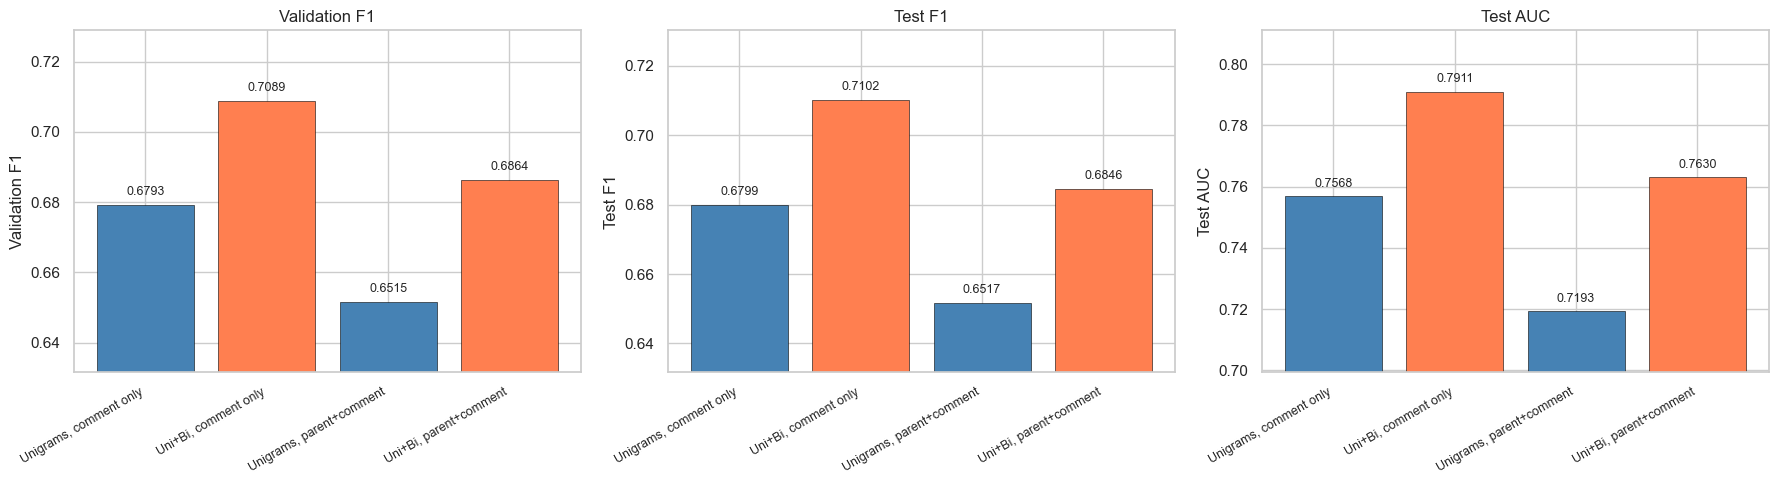

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x = range(len(ablation_df))
labels = ablation_df['config']

for ax, metric, title in zip(axes, ['val_f1', 'test_f1', 'test_auc'],
                              ['Validation F1', 'Test F1', 'Test AUC']):
    bars = ax.bar(x, ablation_df[metric], color=['steelblue', 'coral', 'steelblue', 'coral'],
                  edgecolor='black', linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=9)
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_ylim(min(ablation_df[metric]) - 0.02, max(ablation_df[metric]) + 0.02)
    for bar, val in zip(bars, ablation_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Brief analysis
- Bigrams help substantially. On Test F1, Uni + Bi on comment only goes from 0.6799 to 0.7102, which is significant -> sarcastic phrases like "oh great", "yeah right" are bigrams that unigrams won't be able to capture
- Parent context actually hurts -> across the 3 metrics, adding the parent comment causes the model to perform worse. This could be because TF-IDF just treats the concatenated parent + comment as one flat bag of words, so the parent comment probably just added noise and diluted the signal, especially for a 'simplistic' model like logistic regression. It is unable to see the contrast between the reply and the parent. We can explore this further and see if the parent comment can help, by using a more complex model, such as transformers